# 04 · Reception Estimator (secondary model)

Predicts the probability that a review is **negative** (the 14% minority class), so the content team can prioritise
human audits. Features: reviewer history, playtime, price, platforms, days since release, and draft-time game features.
Game-level aggregates that *are* reception (positive ratio, rating, review counts) are excluded to avoid leakage.

* 5% uniform sample of the 41M reviews (~2M rows)
* Chronological split: train < 2022-01, validation 2022-H1, test >= 2022-07
* SageMaker built-in **XGBoost** training job, then **batch transform** on the test period, then **Model Registry**

In [1]:
# Pin the SageMaker SDK v2 API used by this project (no-op if already installed)
%pip install -q "sagemaker>=2.232,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import warnings

warnings.filterwarnings("ignore")
def find_repo_root():
    """The notebooks import from src/, so the whole repo must be cloned, not just notebooks/."""
    candidates = [os.path.expanduser("~/steam-store-copilot")]
    try:  # the kernel's working directory may have been deleted (e.g. after re-cloning)
        candidates = [os.getcwd(), os.path.dirname(os.getcwd())] + candidates
    except FileNotFoundError:
        os.chdir(os.path.expanduser("~"))
    for path in candidates:
        if os.path.isdir(os.path.join(path, "src")) and os.path.exists(os.path.join(path, "src", "config.py")):
            return path
    raise RuntimeError("Could not find the repo's src/ folder. Clone the full repository in Studio "
                       "(Git > Clone Repository) and open the notebooks from steam-store-copilot/notebooks/.")


REPO_ROOT = find_repo_root()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
print("Repo root:", REPO_ROOT)

import logging

for _name in ("sagemaker", "sagemaker.config", "botocore.credentials"):
    logging.getLogger(_name).setLevel(logging.ERROR)  # keep SDK log noise out of the outputs

import boto3
import sagemaker

from src.config import S3Layout

# Works both inside SageMaker Studio and on a laptop with Learner Lab credentials in ~/.aws/credentials
boto_session = boto3.Session(region_name=boto3.Session().region_name or "us-east-1")
sess = sagemaker.Session(boto_session=boto_session)
region = sess.boto_region_name
if os.path.exists("/opt/ml/metadata/resource-metadata.json"):  # inside SageMaker Studio
    role = sagemaker.get_execution_role(sagemaker_session=sess)
else:  # laptop with Learner Lab credentials: jobs run as the lab's execution role
    account = boto_session.client("sts").get_caller_identity()["Account"]
    role = f"arn:aws:iam::{account}:role/LabRole"
layout = S3Layout(bucket=sess.default_bucket())
sm = boto3.client("sagemaker", region_name=region)
print("Region:", region)
print("Role:  ", role)
print("Bucket:", layout.bucket)

Repo root: /Users/yatharthvardan/Documents/USD/steam-store-copilot


Region: us-east-1
Role:   arn:aws:iam::326278567375:role/LabRole
Bucket: sagemaker-us-east-1-326278567375


In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

from src.config import RECEPTION_MODEL_GROUP
from src.data.loaders import load_recs_games, load_store_games, load_users
from src.data.preprocess import build_tag_dataset
from src.data.s3io import fetch, read_text, stream, write_csv, write_text
from src.models.reception import features as rf

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
reviews = rf.sample_reviews(stream(f"{layout.raw}/recs/recommendations.csv"), frac=0.05)
users = load_users(fetch(f"{layout.raw}/recs/users.csv"))
recs_games = load_recs_games(fetch(f"{layout.raw}/recs/games.csv"))
tag_ds = build_tag_dataset(load_store_games(fetch(f"{layout.raw}/store/games.csv")))
frame = rf.build_reception_frame(reviews, users, recs_games, tag_ds)
splits = rf.chronological_split(frame)
del reviews, users
pd.DataFrame({s: {"rows": len(d), "negative_share": d[rf.LABEL].mean(),
                  "from": d["date"].min().date(), "to": d["date"].max().date()} for s, d in splits.items()}).T

,rows,negative_share,from,to
train,1578144,0.1392,2010-10-15,2021-12-31
val,219365,0.149632,2022-01-01,2022-06-30
test,260231,0.152157,2022-07-01,2022-12-31


In [4]:
prefix = layout.uri("reception")
write_csv(rf.to_xgboost_csv(splits["train"]), f"{prefix}/train/train.csv", index=False, header=False)
write_csv(rf.to_xgboost_csv(splits["val"]), f"{prefix}/validation/validation.csv", index=False, header=False)
write_csv(splits["test"][rf.FEATURES], f"{prefix}/test/test_features.csv", index=False, header=False)
print("Training data written under", prefix)

Training data written under s3://sagemaker-us-east-1-326278567375/steam-store-copilot/reception


In [5]:
from sagemaker.estimator import Estimator
from sagemaker.inputs import TrainingInput

xgb_image = sagemaker.image_uris.retrieve("xgboost", region, version="1.7-1")
xgb = Estimator(
    image_uri=xgb_image, role=role, instance_count=1, instance_type="ml.m5.xlarge",
    output_path=f"{prefix}/models", base_job_name="reception-xgb", sagemaker_session=sess,
    hyperparameters={
        "objective": "binary:logistic", "eval_metric": "aucpr", "num_round": 300,
        "max_depth": 6, "eta": 0.1, "subsample": 0.8, "colsample_bytree": 0.8,
        "tree_method": "hist", "early_stopping_rounds": 20,
        "scale_pos_weight": round(rf.scale_pos_weight(splits["train"][rf.LABEL].values), 3),
    },
)
xgb.fit({"train": TrainingInput(f"{prefix}/train/", content_type="text/csv"),
         "validation": TrainingInput(f"{prefix}/validation/", content_type="text/csv")}, logs=False)
print("Training job:", xgb.latest_training_job.name)


2026-10-17 17:35:13 Starting - Starting the training job

.

.


2026-10-17 17:35:28 Starting - Preparing the instances for training

.

...

.


2026-10-17 17:38:51 Uploading - Uploading generated training model

.


2026-10-17 17:39:04 Completed - Training job completed


Training job: reception-xgb-2026-10-17-17-35-07-793


## Batch transform on the held-out (most recent) period

In [6]:
transformer = xgb.transformer(instance_count=1, instance_type="ml.m5.xlarge",
                              output_path=f"{prefix}/predictions", strategy="MultiRecord",
                              assemble_with="Line", accept="text/csv")
transformer.transform(f"{prefix}/test/test_features.csv", content_type="text/csv", split_type="Line",
                      wait=True, logs=False)
proba = np.array([float(x) for x in read_text(f"{prefix}/predictions/test_features.csv.out").split()])
y_test = splits["test"][rf.LABEL].values
metrics = {"pr_auc": average_precision_score(y_test, proba), "roc_auc": roc_auc_score(y_test, proba),
           "prevalence": float(y_test.mean()), "test_rows": int(len(y_test))}
metrics

.

.

.

.

.

...

.

.

.

!

{'pr_auc': 0.3805169043046328,
 'roc_auc': 0.7526995983589534,
 'prevalence': 0.15215712194165953,
 'test_rows': 260231}

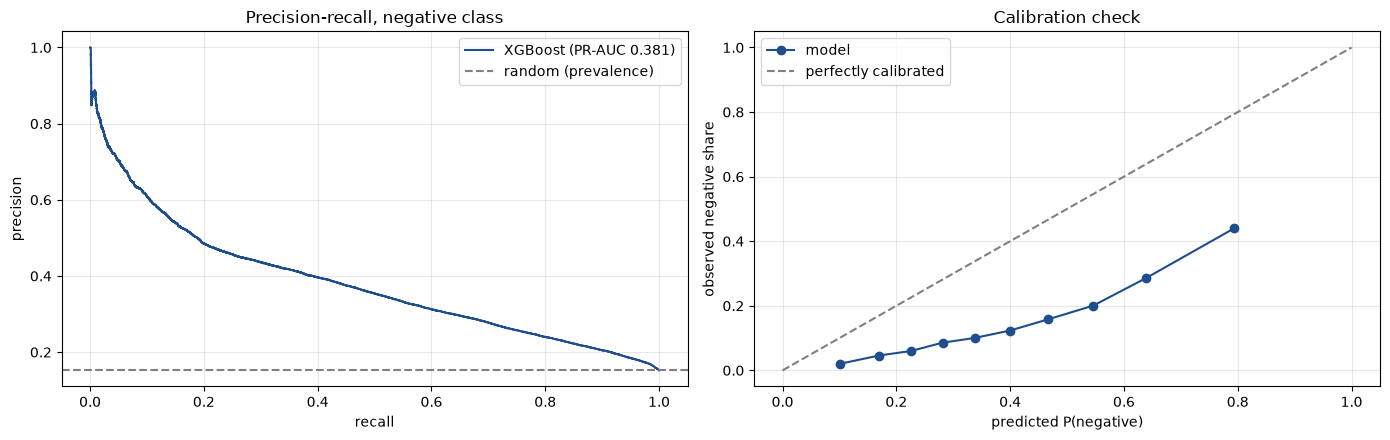

Note: scale_pos_weight inflates probabilities; use the score for ranking, not as a calibrated rate.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
prec, rec, _ = precision_recall_curve(y_test, proba)
axes[0].plot(rec, prec, color="#1f4e8c", label=f"XGBoost (PR-AUC {metrics['pr_auc']:.3f})")
axes[0].axhline(metrics["prevalence"], color="grey", ls="--", label="random (prevalence)")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall, negative class")
axes[0].legend()
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
axes[1].plot(mean_pred, frac_pos, marker="o", color="#1f4e8c", label="model")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", label="perfectly calibrated")
axes[1].set(xlabel="predicted P(negative)", ylabel="observed negative share", title="Calibration check")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Note: scale_pos_weight inflates probabilities; use the score for ranking, not as a calibrated rate.")

In [8]:
scored = splits["test"][["app_id"]].assign(p_negative=proba, negative=y_test)
priority = (scored.groupby("app_id").agg(reviews=("negative", "size"), predicted_negative=("p_negative", "mean"),
                                         actual_negative=("negative", "mean"))
            .query("reviews >= 50").sort_values("predicted_negative", ascending=False))
names = recs_games.set_index("app_id")["title"]
priority.insert(0, "title", names.reindex(priority.index).values)
print("Titles to prioritise for human audit (highest expected negative reception):")
priority.head(10).round(3)

Titles to prioritise for human audit (highest expected negative reception):


,title,reviews,predicted_negative,actual_negative
app_id,,,,
1517290,Battlefield™ 2042,933,0.799,0.478
1236300,Resident Evil Re:Verse,101,0.780,0.624
578080,PUBG: BATTLEGROUNDS,94,0.777,0.436
1665460,eFootball™ 2024,224,0.774,0.473
779340,Total War: THREE KINGDOMS,84,0.763,0.155
903950,Last Oasis,53,0.749,0.604
715400,Frozen Flame,65,0.744,0.308
2012840,Portal with RTX,308,0.731,0.536
1056640,Phantasy Star Online 2 New Genesis,51,0.725,0.431


## Register in the Model Registry

In [9]:
from sagemaker.model_metrics import MetricsSource, ModelMetrics

metrics_uri = write_text(f"{prefix}/evaluation/evaluation.json", json.dumps(
    {"binary_classification_metrics": {"pr_auc": {"value": metrics["pr_auc"]},
                                       "roc_auc": {"value": metrics["roc_auc"]},
                                       "prevalence": {"value": metrics["prevalence"]}}}, indent=2))
package = xgb.register(
    content_types=["text/csv"], response_types=["text/csv"],
    inference_instances=["ml.m5.large"], transform_instances=["ml.m5.xlarge"],
    model_package_group_name=RECEPTION_MODEL_GROUP, approval_status="Approved",
    model_metrics=ModelMetrics(model_statistics=MetricsSource(s3_uri=metrics_uri, content_type="application/json")),
    description="Reception Estimator - XGBoost, P(negative review)",
)
print("Registered:", package.model_package_arn)

Registered: arn:aws:sagemaker:us-east-1:326278567375:model-package/steam-reception-estimator/1
